In [2]:
import pandas as pd

from gaia_variable_stars import plots
from gaia_variable_stars.config import CLASSES, CLEAN_FILE, FEATURE_FILE, FEATURES
from gaia_variable_stars.features import build

pd.set_option("display.max_columns", 50)


In [3]:
data = pd.read_csv(CLEAN_FILE, low_memory=False)
print(data.shape, data["source_id"].nunique(), "stars")

(84278, 31) 2000 stars


In [4]:
feat = build(data)

assert set(CLASSES) <= set(feat["class_name"]), "A class is missing: re-run notebook 02."

feat["class_name"].value_counts()


100%|████████████████████████████████████████████████████████████████████████████████████████████| 2000/2000 [01:38<00:00, 20.29it/s]


class_name
Cepheid                 500
Long-Period Variable    499
Eclipsing Binary        483
RR Lyrae                472
Name: count, dtype: int64

In [5]:
feat[FEATURES].isna().sum()

magnitude_mean     0
magnitude_std      0
magnitude_skew     0
magnitude_kurt     0
amplitude          0
log_period         0
power              0
fourier_amp        0
fourier_ratio      0
bp_rp_color       38
dtype: int64

In [6]:
feat.groupby("class_name")[FEATURES + ["period"]].median().reindex(CLASSES)

,magnitude_mean,magnitude_std,magnitude_skew,magnitude_kurt,amplitude,log_period,power,fourier_amp,fourier_ratio,bp_rp_color,period
class_name,,,,,,,,,,,
RR Lyrae,18.381786,0.168448,-0.442108,-0.844684,0.496695,-0.290694,0.706559,0.206781,0.394078,0.863757,0.512042
Cepheid,16.139688,0.159112,-0.218222,-1.169856,0.451960,0.431632,0.854209,0.209160,0.271147,0.877346,2.701667
Eclipsing Binary,18.431992,0.092257,0.710450,-0.413162,0.264394,-0.649763,0.746611,0.112656,0.265586,1.394193,0.223994
Long-Period Variable,16.177138,0.060993,-0.060555,-0.137891,0.185704,0.671535,0.592962,0.071755,0.254148,4.466151,4.693910


In [7]:
FEATURE_FILE.parent.mkdir(parents=True, exist_ok=True)
feat.to_csv(FEATURE_FILE, index=False)

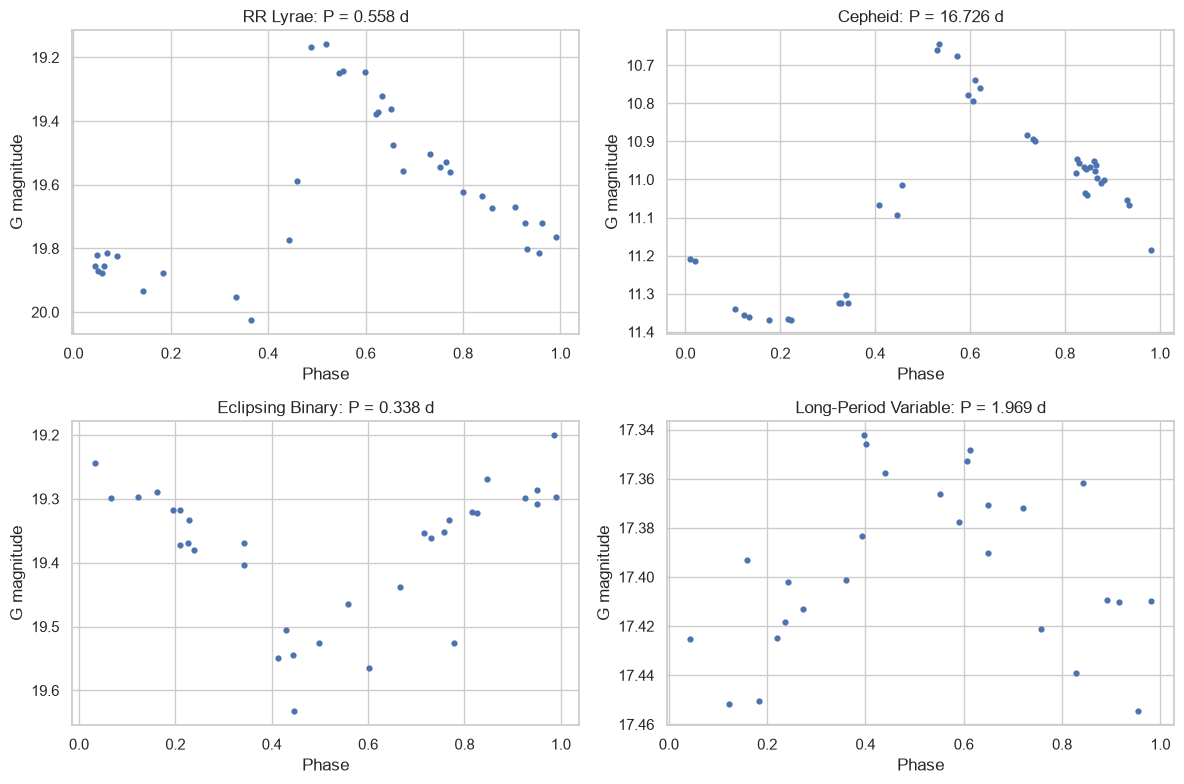

In [8]:
plots.fold(data, feat)

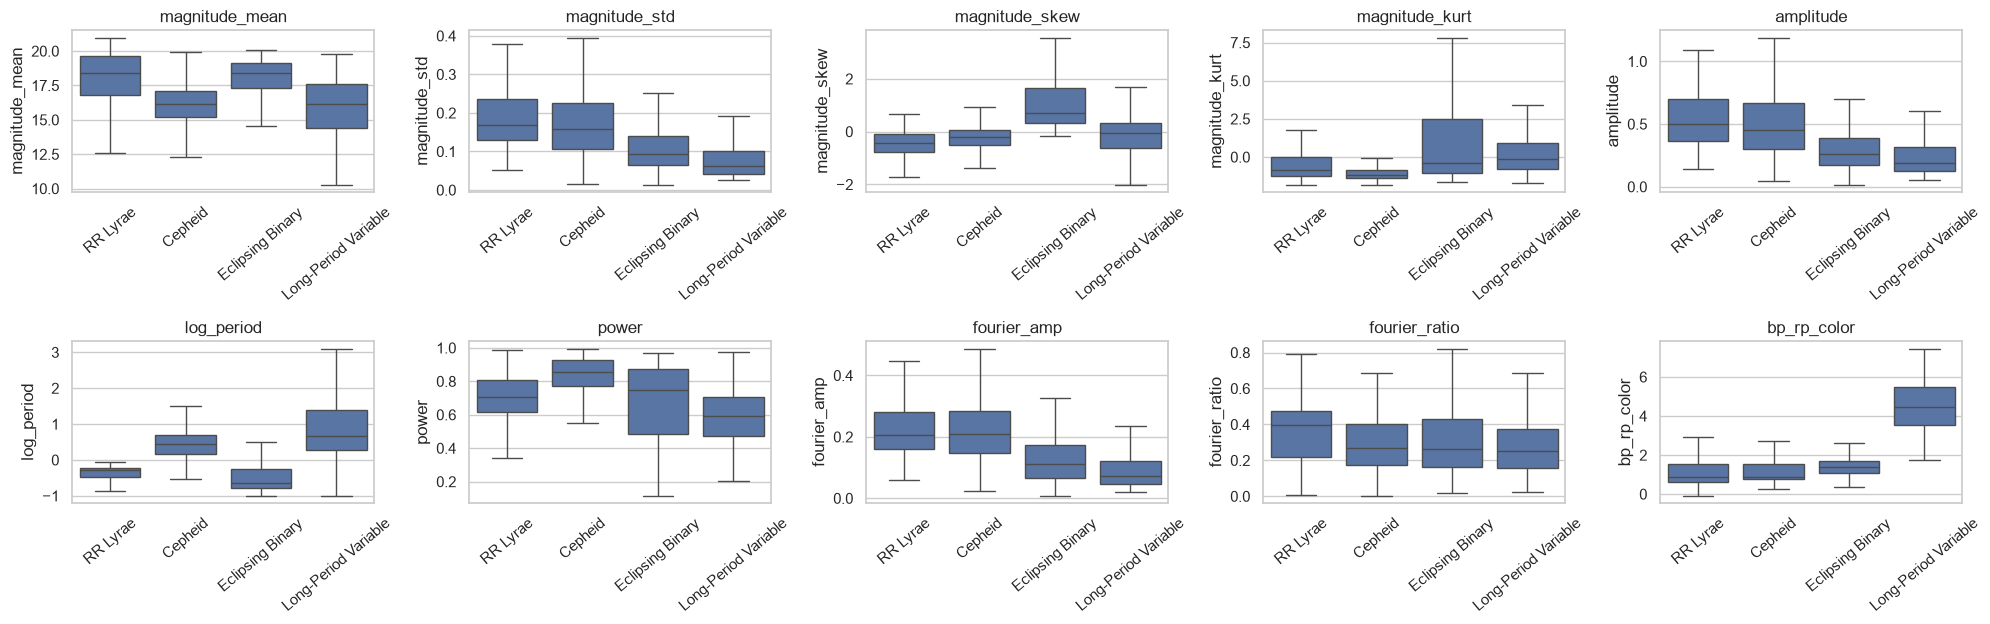

In [9]:
plots.dist(feat)

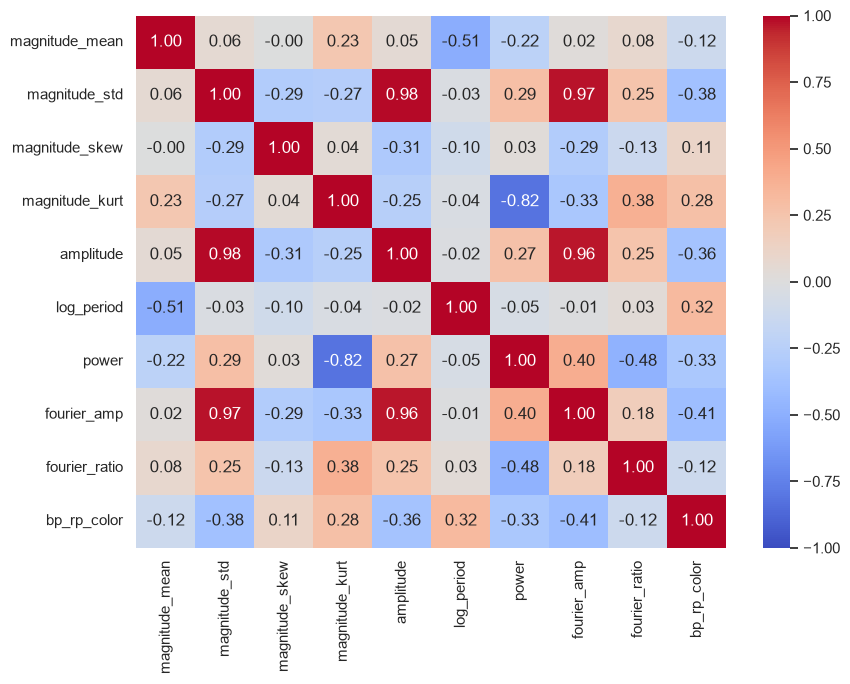

In [10]:
plots.corr(feat)